# Data exploration and Supported tag cut-off

This notebook explores the StackOverflow dataset and chooses which Tags become
**Supported tags**: the Tags frequent enough to be learned and suggested. The decision is
recorded in [ADR 0003](../docs/adr/0003-supported-tag-frequency-cutoff.md) and the chosen
value is the `data.frequency_cutoff` default in [`config.toml`](../config.toml).

The dataset has one row per (Question, Tag) pair. A Tag's **frequency** is the number of
distinct Questions that carry it, not the number of rows.

In [1]:
import tomllib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("..") / "data" / "stackoverflow_posts.csv"
TEST_SHARE = 0.15  # share of Questions held out for the test split
TRAIN_SHARE = 0.70  # assumption until the split ticket fixes it: a 70/15/15 split
CONFIG = tomllib.loads((Path("..") / "config.toml").read_text(encoding="utf-8"))

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

## 1. Integrity checks

### Missing values

A first, default `pandas.read_csv` reports missing Tag names. Looking at the raw file
shows why: the Tag is literally called `null`, which pandas turns into NaN by default.

In [2]:
naive = pd.read_csv(DATA_PATH)
print(naive.isna().sum().to_string())

raw = pd.read_csv(DATA_PATH, keep_default_na=False)
nan_tag_names = raw.loc[naive["tag_name"].isna(), "tag_name"].unique()
print("\nRaw value behind the NaN Tag names:", nan_tag_names)

post_id         0
tag_name        4
tag_id          0
tag_position    0
title           0

Raw value behind the NaN Tag names: <StringArray>
['null']
Length: 1, dtype: str


So the file must be read with NA detection turned off. With that, no value is
missing.

In [3]:
df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[])
print(df.dtypes.to_string())
print("\nEmpty strings per column:")
print((df.astype(str) == "").sum().to_string())
print(f"\nRows: {len(df):,}")

post_id         int64
tag_name          str
tag_id          int64
tag_position    int64
title             str

Empty strings per column:
post_id         0
tag_name        0
tag_id          0
tag_position    0
title           0

Rows: 9,999


### Duplicates and Title consistency

In [4]:
per_question_titles = df.groupby("post_id")["title"].nunique()
checks = {
    "fully duplicated rows": df.duplicated().sum(),
    "duplicated (Question, Tag) pairs": df.duplicated(["post_id", "tag_name"]).sum(),
    "duplicated (Question, tag_position)": df.duplicated(["post_id", "tag_position"]).sum(),
    "Questions whose rows disagree on the Title": (per_question_titles > 1).sum(),
    "Titles with leading/trailing whitespace": (df["title"] != df["title"].str.strip()).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
fully duplicated rows,0
"duplicated (Question, Tag) pairs",0
"duplicated (Question, tag_position)",0
Questions whose rows disagree on the Title,0
Titles with leading/trailing whitespace,0


### `tag_id` versus `tag_name`

In [5]:
names_per_id = df.groupby("tag_id")["tag_name"].nunique().max()
ids_per_name = df.groupby("tag_name")["tag_id"].nunique().max()
print(f"Max names per tag_id: {names_per_id}, max ids per tag_name: {ids_per_name}")

Max names per tag_id: 1, max ids per tag_name: 1


`tag_id` maps one-to-one to `tag_name`, so either can identify a Tag.

### `tag_position` per Question

If every Question kept all its Tags, positions would run 0, 1, …, k−1.

In [6]:
positions = df.groupby("post_id")["tag_position"].agg(["min", "max", "count"])
not_from_zero = positions["min"] != 0
gaps = positions["max"] - positions["min"] + 1 != positions["count"]
print(f"Position range across the dataset: {df['tag_position'].min()}..{df['tag_position'].max()}")
print(f"Questions whose positions do not start at 0: {not_from_zero.sum()}")
print(f"Questions with a gap in their positions:     {gaps.sum()}")
print(f"Questions with either anomaly:               {(not_from_zero | gaps).sum()}")
positions[not_from_zero | gaps].head()

Position range across the dataset: 0..4
Questions whose positions do not start at 0: 30
Questions with a gap in their positions:     120
Questions with either anomaly:               149


,min,max,count
post_id,,,
1987833,0,3,3
1987883,1,1,1
1987981,1,1,1
1988033,0,3,3
1988202,1,1,1


Some Questions are missing positions, so the export dropped some of their Tags
(the original Question had more Tags than the dataset shows). The file also has exactly
9,999 data rows, which looks like an export limit: the last Question may have lost Tags too.
We cannot recover the missing Tags, and every row that is present is valid.

### Anomalies and how data preparation (#5) must handle them

| Anomaly | Handling in #5 |
| --- | --- |
| The Tag `null` is read as NaN by default | Read the CSV with `keep_default_na=False` (or equivalent) so `null` stays a Tag name; fail loudly on a truly empty Tag or Title. |
| `tag_position` has gaps or does not start at 0 for some Questions | Ignore `tag_position`: a Question's Tags are the set of its rows. Do not use positions as indices. |
| Possibly truncated last Question (9,999-row export limit) | No special handling: keep the Tags present. |
| No duplicated rows, no Title disagreement, `tag_id` ↔ `tag_name` one-to-one | Still assert these invariants on load, so a new export that breaks them fails loudly. |

## 2. Shape of the data

In [7]:
questions = df.groupby("post_id").agg(title=("title", "first"), tags=("tag_name", list))
tag_frequency = df.groupby("tag_name")["post_id"].nunique().sort_values(ascending=False)
n_questions = len(questions)
n_pairs = len(df)
print(f"Questions:       {n_questions:,}")
print(f"Distinct Tags:   {len(tag_frequency):,}")
print(f"(Question, Tag): {n_pairs:,}")
print(f"Tags in >= 50 Questions: {(tag_frequency >= 50).sum()}")
print(f"Tags in exactly 1 Question: {(tag_frequency == 1).sum()}")

Questions:       4,609
Distinct Tags:   682
(Question, Tag): 9,999
Tags in >= 50 Questions: 33
Tags in exactly 1 Question: 83


These match the first look described in the ticket (4,609 Questions, 682 Tags,
33 Tags with at least 50 Questions, 83 singletons), once `null` is counted as a Tag.

### Tags per Question

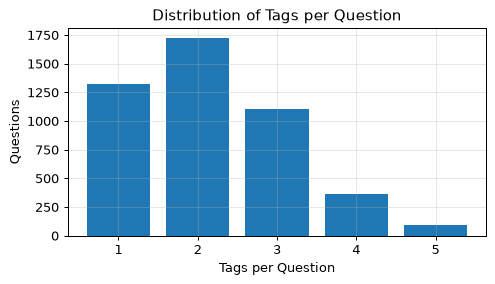

tags,1,2,3,4,5
questions,1323,1727,1104,365,90


In [8]:
tags_per_question = questions["tags"].str.len()
counts = tags_per_question.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(counts.index, counts.values, color="tab:blue")
ax.set_xlabel("Tags per Question")
ax.set_ylabel("Questions")
ax.set_title("Distribution of Tags per Question")
plt.show()
counts.rename("questions").to_frame().T

### Title length

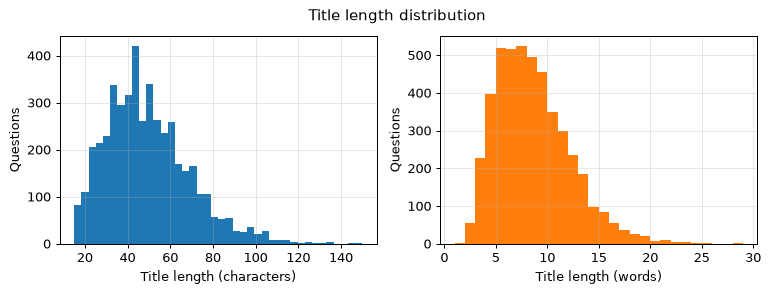

,characters,words
count,4609.0,4609.0
mean,49.4,8.1
std,19.5,3.6
min,15.0,1.0
50%,47.0,8.0
95%,85.0,15.0
99%,105.0,19.0
max,150.0,28.0


In [9]:
title_chars = questions["title"].str.len()
title_words = questions["title"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(title_chars, bins=40, color="tab:blue")
axes[0].set_xlabel("Title length (characters)")
axes[0].set_ylabel("Questions")
axes[1].hist(title_words, bins=range(1, title_words.max() + 2), color="tab:orange")
axes[1].set_xlabel("Title length (words)")
axes[1].set_ylabel("Questions")
fig.suptitle("Title length distribution")
plt.show()
pd.DataFrame(
    {
        "characters": title_chars.describe(percentiles=[0.5, 0.95, 0.99]),
        "words": title_words.describe(percentiles=[0.5, 0.95, 0.99]),
    }
).round(1)

Titles are short: the 95th percentile is 15 words and the 99th is 19 words. Subword
tokenisation adds tokens, so ticket #10 should measure the token length directly, but a
maximum sequence length well below 64 tokens should cover almost every Title.

### Most frequent Tags

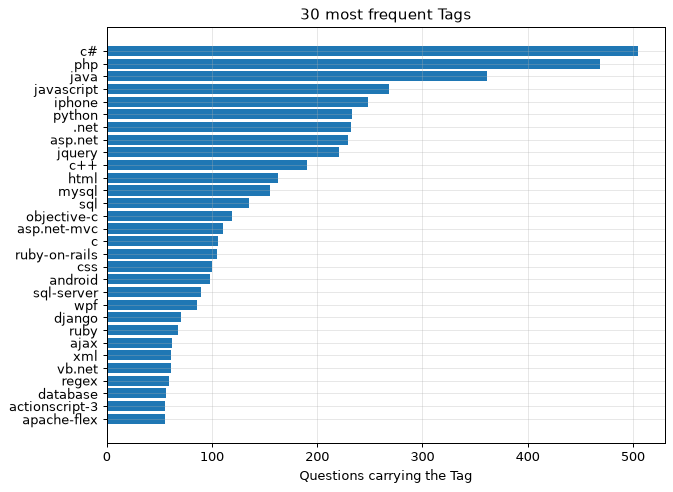

In [10]:
top = tag_frequency.head(30)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index[::-1], top.values[::-1], color="tab:blue")
ax.set_xlabel("Questions carrying the Tag")
ax.set_title("30 most frequent Tags")
plt.show()

### The long tail

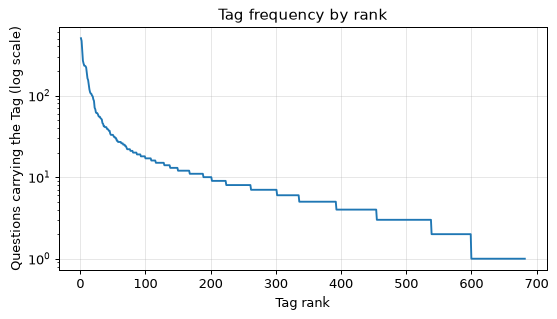

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, len(tag_frequency) + 1), tag_frequency.values, color="tab:blue")
ax.set_yscale("log")
ax.set_xlabel("Tag rank")
ax.set_ylabel("Questions carrying the Tag (log scale)")
ax.set_title("Tag frequency by rank")
plt.show()

A handful of Tags are very common and most Tags are rare: a classic long tail. A
Tagger cannot learn a Tag from one or two Titles, hence the need for a cut-off.

## 3. Cut-off analysis

For each candidate cut-off N, the Supported tags are the Tags with frequency ≥ N. We
measure:

- the number of Supported tags;
- **Question coverage**: the share of Questions that keep at least one Supported tag (the
  others are dropped);
- **pair coverage**: the share of (Question, Tag) pairs that are kept;
- the expected number of examples of the rarest Supported tag in the test split
  (≈ 0.15 × N) and in the training split (≈ 0.70 × N).

In [12]:
def cutoff_stats(cutoff: int) -> dict[str, float]:
    supported = tag_frequency.index[tag_frequency >= cutoff]
    kept = df[df["tag_name"].isin(supported)]
    kept_questions = kept["post_id"].nunique()
    return {
        "supported_tags": len(supported),
        "question_coverage": kept_questions / n_questions,
        "pair_coverage": len(kept) / n_pairs,
        "expected_test_examples": TEST_SHARE * cutoff,
        "expected_train_examples": TRAIN_SHARE * cutoff,
        "questions_dropped": n_questions - kept_questions,
    }


curve = pd.DataFrame({n: cutoff_stats(n) for n in range(1, 101)}).T
curve.index.name = "N"
int_columns = ["supported_tags", "questions_dropped"]
curve[int_columns] = curve[int_columns].astype(int)

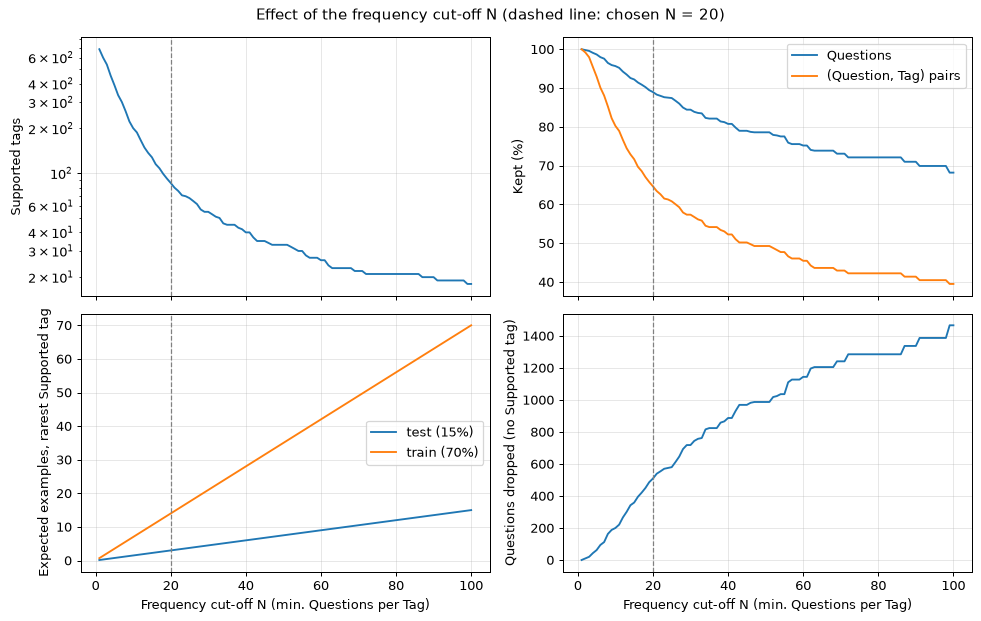

In [13]:
FREQUENCY_CUTOFF = CONFIG["data"]["frequency_cutoff"]  # configured default, justified below

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
axes[0, 0].plot(curve.index, curve["supported_tags"])
axes[0, 0].set_ylabel("Supported tags")
axes[0, 0].set_yscale("log")
axes[0, 1].plot(curve.index, 100 * curve["question_coverage"], label="Questions")
axes[0, 1].plot(curve.index, 100 * curve["pair_coverage"], label="(Question, Tag) pairs")
axes[0, 1].set_ylabel("Kept (%)")
axes[0, 1].legend()
axes[1, 0].plot(curve.index, curve["expected_test_examples"], label="test (15%)")
axes[1, 0].plot(curve.index, curve["expected_train_examples"], label="train (70%)")
axes[1, 0].set_ylabel("Expected examples, rarest Supported tag")
axes[1, 0].legend()
axes[1, 1].plot(curve.index, curve["questions_dropped"])
axes[1, 1].set_ylabel("Questions dropped (no Supported tag)")
for ax in axes.flat:
    ax.axvline(FREQUENCY_CUTOFF, color="grey", linestyle="--", linewidth=1)
for ax in axes[1]:
    ax.set_xlabel("Frequency cut-off N (min. Questions per Tag)")
fig.suptitle(f"Effect of the frequency cut-off N (dashed line: chosen N = {FREQUENCY_CUTOFF})")
fig.tight_layout()
plt.show()

### Landmark values

In [14]:
landmarks = curve.loc[[1, 5, 10, 15, 20, 30, 50]].copy()
landmarks["question_coverage"] = landmarks["question_coverage"].map("{:.1%}".format)
landmarks["pair_coverage"] = landmarks["pair_coverage"].map("{:.1%}".format)
landmarks.round({"expected_test_examples": 2, "expected_train_examples": 1})

,supported_tags,question_coverage,pair_coverage,expected_test_examples,expected_train_examples,questions_dropped
N,,,,,,
1,682,100.0%,100.0%,0.15,0.7,0
5,392,98.7%,92.9%,0.75,3.5,62
10,201,95.7%,80.2%,1.50,7.0,200
15,128,92.2%,71.6%,2.25,10.5,359
20,86,89.0%,64.6%,3.00,14.0,509
30,55,84.4%,57.4%,4.50,21.0,718
50,33,78.6%,49.3%,7.50,35.0,987


## 4. Decision

Rule of thumb: every Supported tag should appear in the training split several times and
in the test split at least a few times, otherwise a Tagger cannot learn it and its
per-Tag score (and so macro-F1) is noise. Made concrete: **the rarest Supported tag must
expect at least 3 examples in the test split**, i.e. 0.15 × N ≥ 3, so N ≥ 20. With a
70/15/15 split (to be fixed by the split ticket) that also means about 14 training examples.

- **N ≤ 10** keeps 96–100% of Questions but leaves the rarest Supported tags with at most
  1.5 expected test examples: their per-Tag F1 is close to either 0 or 1, and macro-F1
  becomes noise. They also get at most about 7 training examples, too few to learn a Tag
  from Titles alone.
- **N = 50** is comfortable for learning but keeps only 33 Tags and drops over a fifth of
  the Questions and half of the (Question, Tag) pairs.
- **N = 20** is the smallest cut-off that meets the rule, and it still keeps 89% of the
  Questions.

Three is an *expected* count: with a purely random split, a Tag carried by exactly 20
Questions still lands at most once in the test split about 18% of the time. The split ticket
should therefore stratify on Tags so that the rarest Supported tags reach the test split.

**Chosen cut-off: N = 20.**

In [15]:
chosen = curve.loc[FREQUENCY_CUTOFF]
print(f"Frequency cut-off N:  {FREQUENCY_CUTOFF}")
print(f"Supported tags:       {int(chosen['supported_tags'])} of {len(tag_frequency)}")
print(f"Question coverage:    {chosen['question_coverage']:.1%}")
print(f"Pair coverage:        {chosen['pair_coverage']:.1%}")
print(f"Questions dropped:    {int(chosen['questions_dropped'])}")

Frequency cut-off N:  20
Supported tags:       86 of 682
Question coverage:    89.0%
Pair coverage:        64.6%
Questions dropped:    509


Questions left with no Supported tag are dropped by data preparation. The cut-off is
configurable through `data.frequency_cutoff` in `config.toml`; this notebook only justifies
its default value, which the cells above read from that file.